# LFPG – источники временных рядов и пилот ADSB.lol

**Этап 02 · 12 октября 2026**

Вопрос: можно ли получить последовательные наблюдения на малых высотах около LFPG из доступного открытого архива?

Проверка сайтов источников показала: [Zenodo](https://zenodo.org/records/10210178) публикует метаданные, а [репозиторий авторов](https://github.com/figuetbe/OSN23-GoA) не содержит исходных траекторий. [Исторический OpenSky Trino](https://openskynetwork.github.io/opensky-api/trino.html) требует одобренного доступа, которого сейчас нет. [REST tracks](https://openskynetwork.github.io/opensky-api/rest.html) ограничен последними 30 днями и не заменяет Trino для старого периода.

Практический путь – локально сохраненный глобальный архив [ADSB.lol за 15.01.2025](https://github.com/adsblol/globe_history_2025). Его папка usa не ограничивает географию содержимого. Этот пилот относится к новому периоду; метки предыдущей таблицы на него не переносятся.

In [1]:
from pathlib import Path
import json
import hashlib
import platform
import importlib.metadata
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Находим проект и локальный реестр проверенных источников
BASE = Path.cwd()
if BASE.name == 'notebooks':
    BASE = BASE.parent
PROJECT = BASE.parents[1]
registry = json.loads((BASE / 'reports/02_source_registry.json').read_text(encoding='utf-8'))
display(pd.DataFrame(registry['sources'])[['name', 'role', 'access', 'limitation']])
DATE = '2025-01-15'
OUTPUT = BASE / 'data' / DATE
RED, GREEN = '#D65A4A', '#00897B'
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

# При отсутствии результата повторяем потоковый пилот из локального архива
sys.path.insert(0, str(PROJECT / 'scripts'))
from lfpg_archive_pilot import scan
if not (OUTPUT / 'pilot_manifest.json').is_file():
    config = json.loads((PROJECT / 'configs/sources.json').read_text(encoding='utf-8'))
    old = (PROJECT / config['airport_summary']).resolve().parents[2]
    scan(old, BASE, DATE)
manifest = json.loads((OUTPUT / 'pilot_manifest.json').read_text(encoding='utf-8'))
points = pd.read_parquet(OUTPUT / 'region_points.parquet')
traces = pd.read_csv(OUTPUT / 'candidate_traces.csv', dtype={'icao24': str})
assert len(points) == manifest['region_rows']
assert len(traces) == manifest['candidate_trace_files']
# Сверяем исходные объекты кандидатов с хешами членов TAR
for item in traces.itertuples(index=False):
    with (OUTPUT / item.raw_copy).open('rb') as stream:
        assert hashlib.file_digest(stream, 'sha256').hexdigest() == item.member_sha256
# Сохраняем версии библиотек без машинных путей
environment = {'python': platform.python_version(), 'packages': {
    name: importlib.metadata.version(name) for name in ['pandas', 'numpy', 'matplotlib', 'pyarrow', 'nbformat']}}
(BASE / 'reports/02_environment.json').write_text(
    json.dumps(environment, indent=2), encoding='utf-8')
# Фиксируем хеши производных данных отдельно от хешей исходного архива
derived_hashes = {}
for filename in ['region_points.parquet', 'candidate_traces.csv']:
    with (OUTPUT / filename).open('rb') as stream:
        derived_hashes[filename] = hashlib.file_digest(stream, 'sha256').hexdigest()
(BASE / 'reports/02_data_provenance.json').write_text(json.dumps({
    'date': DATE, 'archives': manifest['archives'], 'derived_sha256': derived_hashes,
    'bbox': manifest['bbox'], 'candidate_max_altitude_ft': manifest['candidate_max_altitude_ft'],
    'full_traces_checked': manifest['full_traces_checked']}, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([{'Показатель': key, 'Значение': value}
    for key, value in manifest.items() if key not in ['archives', 'bbox']]))

,name,role,access,limitation
0,Zenodo 10210178,Реестр полетов и меток 2019–2023,Открытый Parquet; уже сохранен локально,Метаданные не содержат полного временного ряда
1,OSN23-GoA,Код и описание исследования авторов,Открытый репозиторий,README прямо указывает отсутствие исходных тра...
2,OpenSky Trino,Исторические state vectors для связи со старым...,Заявка и одобрение; одобренного доступа сейчас...,Доступ ограничен категориями заявителей; всегд...
3,OpenSky REST tracks,Недавние треки,Публичная документация API,История tracks не глубже 30 дней; не подходит ...
4,ADSB.lol 2025,Открытые глобальные суточные траектории; пилот...,Открытый архив ODbL-1.0; выбранный день уже со...,Новый период; метки GoA необходимо определить ...


,Показатель,Значение
0,date,2025-01-15
1,full_traces_checked,59714
2,candidate_trace_files,670
3,region_rows,109116
4,region_ground_rows,0
5,numeric_altitude_min_ft,-275.0
6,candidate_max_altitude_ft,10000
7,airport_assignment_verified,False
8,goaround_labels_created,False
9,license,ODbL-1.0


## Правила пилота и семантика полей

TAR читается последовательно из двух частей, без полного распаковывания. Все части сверяются по размеру и SHA256 с сохраненным манифестом загрузки. Все полные trace JSON выбранного дня проверяются на пространственное совпадение. Исходные объекты кандидатов сохраняются целиком в игнорируемой папке data.

Поиск использует прямоугольник 48,7–49,3° N; 2,0–3,0° E и наличие хотя бы одной числовой высоты не выше 10000 ft. Это техническое ограничение пилота, не граница стабилизированного захода. В область попадают соседние аэропорты, вылеты и пролеты.

По [формату readsb](https://github.com/wiedehopf/readsb/blob/dev/README-json.md) время равно timestamp + смещение точки, высота дана в ft, скорость над землей в knots, вертикальная скорость в ft/min. Флаг 1 означает устаревшую позицию; флаг 8 – геометрическую высоту; флаг 4 – геометрическую вертикальную скорость. Значение ground сохраняется отдельно и не подменяется числовой высотой. Высота не является AGL; скорость над землей не подменяет IAS.

База ADSB.lol распространяется под ODbL-1.0. В Git сохраняются код и агрегаты; исходные объекты и производные точки остаются локальными.

In [2]:
# Описываем заполненность полей без интерполяции и исправления значений
coverage = pd.DataFrame([{'Поле': field, 'Строк с данными': int(points[field].notna().sum()),
                          'Доля': points[field].notna().mean()}
    for field in ['altitude_ft', 'speed_knots', 'track_deg', 'vertical_rate_fpm',
                  'geoaltitude_ft', 'ias_knots', 'position_source']])
coverage.to_csv(BASE / 'reports/02_field_coverage.csv', index=False)
display(coverage)

# Диагностические уровни относятся к исходной высоте, а не высоте над аэродромом
barometric = points.loc[~points.geometric_altitude & ~points.stale_position].copy()
levels = pd.DataFrame([{'Уровень': f'Не выше {height} ft',
                        'Строк': int(barometric.altitude_ft.le(height).sum()),
                        'Треков': barometric.loc[barometric.altitude_ft.le(height), 'trace_id'].nunique()}
                       for height in [10000, 5000, 2000, 1000, 500]])
levels.to_csv(BASE / 'reports/02_low_altitude_counts.csv', index=False)
display(levels)

# Интервалы считаем внутри файлов; разрывы и дубли остаются видимыми
ordered = points.sort_values(['trace_id', 'time'])
gaps = ordered.groupby('trace_id').time.diff()
positive = gaps[gaps > 0]
quality = {'rows': len(points), 'traces': len(traces),
           'duplicate_trace_time_rows': int(points.duplicated(['trace_id', 'time']).sum()),
           'stale_position_rows': int(points.stale_position.sum()),
           'geometric_altitude_rows': int(points.geometric_altitude.sum()),
           'ground_rows': int(points.ground.sum()),
           'median_positive_gap_s': float(positive.median()),
           'p95_positive_gap_s': float(positive.quantile(.95)),
           'max_positive_gap_s': float(positive.max()),
           'airport_assignment_verified': False, 'goaround_labels_created': False}
(BASE / 'reports/02_pilot_quality.json').write_text(
    json.dumps(quality, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([quality]))

,Поле,Строк с данными,Доля
0,altitude_ft,109106,0.999908
1,speed_knots,106522,0.976227
2,track_deg,106481,0.975851
3,vertical_rate_fpm,107930,0.989131
4,geoaltitude_ft,106934,0.980003
5,ias_knots,99209,0.909207
6,position_source,109116,1.000000


,Уровень,Строк,Треков
0,Не выше 10000 ft,89452,666
1,Не выше 5000 ft,62491,665
2,Не выше 2000 ft,17974,652
3,Не выше 1000 ft,5506,565
4,Не выше 500 ft,1617,346


,rows,traces,duplicate_trace_time_rows,stale_position_rows,geometric_altitude_rows,ground_rows,median_positive_gap_s,p95_positive_gap_s,max_positive_gap_s,airport_assignment_verified,goaround_labels_created
0,109116,670,0,4647,0,0,3.71,16.66,78835.12,False,False


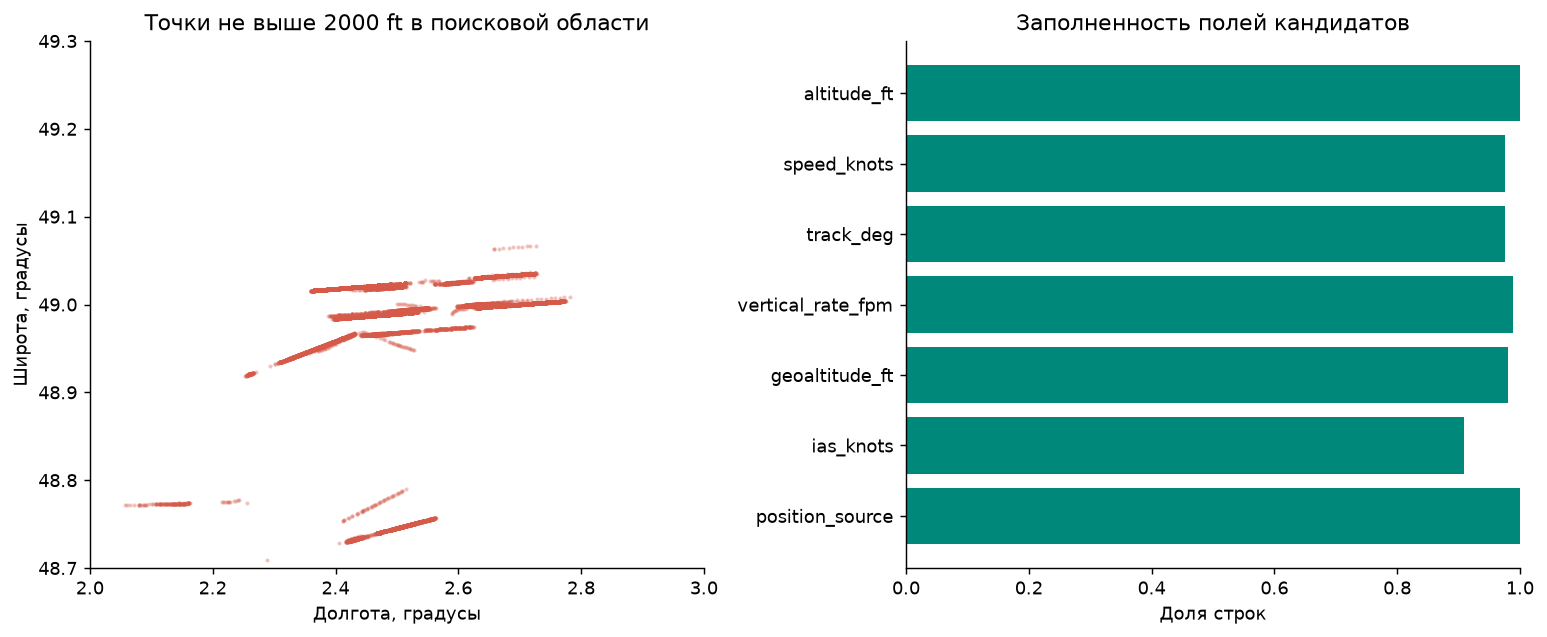

In [3]:
# Показываем пространственное покрытие и заполненность динамических полей
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sample = barometric.loc[barometric.altitude_ft.le(2000)]
axes[0].scatter(sample.lon, sample.lat, s=2, color=RED, alpha=.25)
axes[0].set(title='Точки не выше 2000 ft в поисковой области',
            xlabel='Долгота, градусы', ylabel='Широта, градусы')
axes[0].set_xlim(2.0, 3.0)
axes[0].set_ylim(48.7, 49.3)
axes[1].barh(coverage['Поле'], coverage['Доля'], color=GREEN)
axes[1].set(title='Заполненность полей кандидатов', xlabel='Доля строк', xlim=(0, 1))
axes[1].invert_yaxis()
fig.tight_layout()
for ext in ['png', 'svg']:
    fig.savefig(BASE / f'figures/02_pilot_coverage.{ext}', bbox_inches='tight')
plt.show()

## Пример наблюдаемой динамики

Для иллюстрации выделяем фрагменты по разрывам более 60 секунд и ищем снижающийся фрагмент с низкими точками в прямоугольнике 49,00–49,04° N; 2,50–2,66° E. Эта малая область служит дополнительным географическим поиском около LFPG, а не доказательством посадки на конкретную ВПП. Из кандидатов выбирается самый длинный фрагмент с нисходящей динамикой; показаны последние 10 минут наблюдений.

Выбор иллюстрации ретроспективный. Он не используется как правило доступности данных в онлайн-прогнозе и не определяет норму скорости или вертикальной скорости.

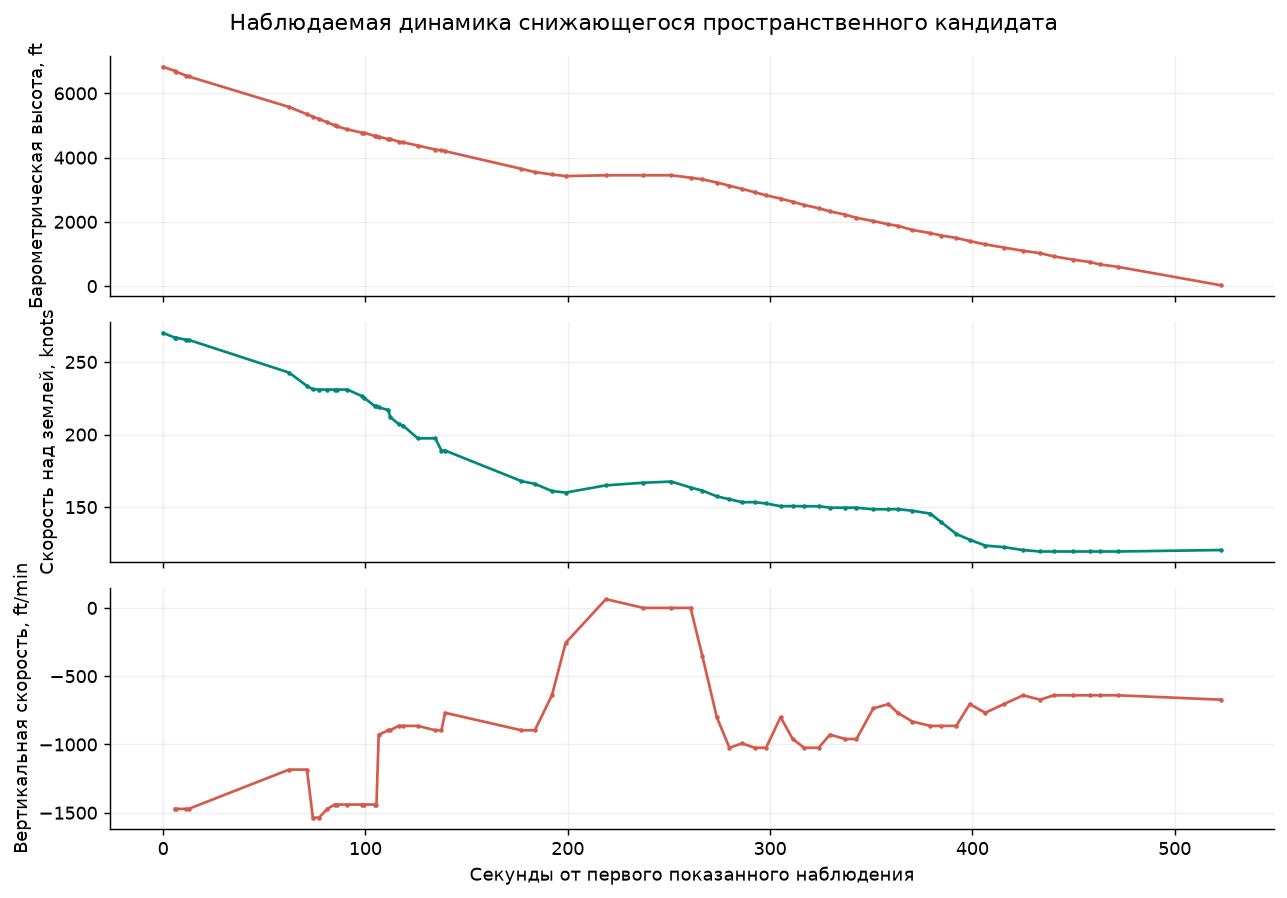

Пример trace_id: 1b5ad3ba490f1a9c строк: 65


In [4]:
# Разделяем траектории по разрывам для описательной иллюстрации
clean = barometric.sort_values(['trace_id', 'time']).copy()
clean['fragment'] = ((clean.trace_id != clean.trace_id.shift())
                     | clean.groupby('trace_id').time.diff().gt(60)).cumsum()
near = clean.lat.between(49.00, 49.04) & clean.lon.between(2.50, 2.66)
low = near & clean.altitude_ft.between(0, 1000) & clean.vertical_rate_fpm.lt(0)
candidate_ids = clean.loc[low, 'fragment'].unique()
options = []
for identifier in candidate_ids:
    group = clean.loc[clean.fragment.eq(identifier)]
    if len(group) >= 10 and group.altitude_ft.iloc[-1] < group.altitude_ft.iloc[0]:
        options.append((len(group), identifier))
assert options, 'Нет подходящего фрагмента для иллюстрации'
chosen = max(options)[1]
example = clean.loc[clean.fragment.eq(chosen)].copy()
example = example.loc[example.time.ge(example.time.max() - 600)]
example['elapsed_s'] = example.time - example.time.min()
example_id = str(example.trace_id.iloc[0])
print('Пример trace_id:', example_id, 'строк:', len(example))
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, field, label, color in zip(axes,
    ['altitude_ft', 'speed_knots', 'vertical_rate_fpm'],
    ['Барометрическая высота, ft', 'Скорость над землей, knots', 'Вертикальная скорость, ft/min'],
    [RED, GREEN, RED]):
    ax.plot(example.elapsed_s, example[field], color=color, marker='.', markersize=3)
    ax.set_ylabel(label)
    ax.grid(alpha=.2)
axes[-1].set_xlabel('Секунды от первого показанного наблюдения')
fig.suptitle('Наблюдаемая динамика снижающегося пространственного кандидата')
fig.tight_layout()
for ext in ['png', 'svg']:
    fig.savefig(BASE / f'figures/02_example_dynamics.{ext}', bbox_inches='tight')
plt.show()
(BASE / 'reports/02_example_selection.json').write_text(json.dumps({
    'trace_id': example_id, 'rows': len(example), 'gap_split_s': 60,
    'display_window_s': 600, 'airport_assignment_verified': False,
    'retrospective_illustration': True}, indent=2), encoding='utf-8')

## Что доказывает этот пилот

Наличие последовательных низких наблюдений подтверждает техническую возможность исследовать динамику в регионе на выбранный день. Оно еще не подтверждает принадлежность к LFPG, покрытие до 300 ft AGL, число посадок или наличие уходов.

Полный проход проверил 59714 trace JSON и выделил 670 пространственных треков-кандидатов, 109116 точек в широкой области. После исключения устаревших позиций и геометрической высоты осталось 1617 точек с исходной барометрической высотой не выше 500 ft. Скорость над землей заполнена примерно в 97,62% строк, вертикальная скорость – в 98,91%, IAS – в 90,92%. Эти доли относятся к сохраненным пространственным кандидатам, а не выборке конечных заходов LFPG.

Медиана положительных интервалов внутри треков – 3,71 с, P95 – 16,66 с. Максимум около 21,9 часа показывает, что суточный трек нельзя считать непрерывным заходом. Ground-точки отсутствуют; отрицательные барометрические высоты сохранены как исходные значения. Причины и высотная поправка пока не установлены.

Следующий этап – геометрия LFPG на дату пилота, выделение прибытия и направления ВПП, проверка высотной системы и разрывов конечного участка. Затем проводится отдельная проверка кандидатов на GoA. Один день не дает репрезентативной частоты событий и не заменяет независимую выборку.

Возможная будущая тема доклада – доступность наблюдаемой динамики конечного захода и влияние пропусков на время предупреждения. На текущем этапе это направление исследования, а не заявленная новизна.